# RT-IoT2022 — Analyse exploratoire et nettoyage des données
## Mini-projet IA & Machine Learning — V1 (sans modèle)

**Membres du groupe :**
- Mohamed Rached Ben Abderrazak
- Yasmine Hasnaoui
- Ahmed Smaili
- Mohamed Chrif Zammouri

**Objectif de cette V1 :** comprendre le jeu de données, analyser sa qualité, effectuer un nettoyage initial et documenter les décisions. **Aucun modèle de machine learning n'est entraîné dans cette version.**

## 1. Problématique et objectif

Le projet porte sur la détection de trafic malveillant dans un réseau IoT à partir de statistiques décrivant des flux réseau. Notre objectif final est de distinguer le trafic normal du trafic d'attaque et, si possible, de reconnaître les familles d'attaques.

Cette V1 se limite à la compréhension des données, à l'exploration statistique et au nettoyage. La modélisation et l'évaluation prédictive seront réservées à une version ultérieure.

## 2. Source des données

Dataset **RT-IoT2022**, UCI Machine Learning Repository : [page du dataset](https://archive.ics.uci.edu/dataset/942/rt-iot2022).

Le dataset brut déjà utilisé dans le notebook L1 est lu depuis le dossier local `../Data/raw/dataset.csv`. Aucun téléchargement n’est effectué. Cette V1 suppose que le dossier `Data/raw` et le fichier `dataset.csv` existent déjà dans la même organisation de projet. Le dataset brut ne doit pas être déposé sur Classroom.

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)

# Dataset brut déjà téléchargé et utilisé dans le notebook L1
DATA_PATH = Path("../Data/raw/dataset.csv")
print("Chemin local du dataset :", DATA_PATH.resolve())


Chemin local du dataset : C:\Users\user\Desktop\Machine_learning_project\Data\raw\dataset.csv


### 2.1 Chargement local du dataset brut

In [40]:
# Charger le dataset brut depuis le dossier local (aucun téléchargement)
raw_df = pd.read_csv(DATA_PATH)

# Création de la cible binaire label, comme dans le notebook L1
NORMAL_KEYS = ("mqtt", "thing", "wipro", "alexa")
is_normal = raw_df["Attack_type"].str.lower().str.contains("|".join(NORMAL_KEYS), na=False)
raw_df["label"] = (~is_normal).astype(int)

print("Données chargées depuis le dataset brut local.")
print("label : 0 = benign, 1 = attack")
print(raw_df["label"].value_counts())


Données chargées depuis le dataset brut local.
label : 0 = benign, 1 = attack
label
1    110610
0     12507
Name: count, dtype: int64


## 3. Dimensions et aperçu général

In [41]:
print(f"Nombre d'observations : {raw_df.shape[0]:,}")
print(f"Nombre de colonnes : {raw_df.shape[1]}")
raw_df.head()

Nombre d'observations : 123,117
Nombre de colonnes : 86


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type,label
0,0,38667,1883,tcp,mqtt,32.0116,9,5,3,3,0.2811,0.1562,0.4373,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.4444,13.1159,0.0,23.0,32.0,6.4,9.5551,0.0,33.0,108.0,7.7143,11.6185,761.9858,2.9729e+07,3.2012e+07,4.0014e+06,1.0403e+07,4438.8771,1.5117e+06,2.0264e+06,506597.7573,680406.1471,761.9858,2.9729e+07,3.2012e+07,2.4624e+06,8.1997e+06,3.3738,3.0,1.6667,25.3333,10.6667,0.0,0.0,0.0,0.0,0.0,0.0,2.2824e+06,2.2824e+06,2.2824e+06,2.2824e+06,0.0,2.9729e+07,2.9729e+07,2.9729e+07,2.9729e+07,0.0,64240,26847,502,MQTT_Publish,0
1,1,51143,1883,tcp,mqtt,31.8836,9,5,3,3,0.2823,0.1568,0.4391,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.4444,13.1159,0.0,23.0,32.0,6.4,9.5551,0.0,33.0,108.0,7.7143,11.6185,247.0016,2.9855e+07,3.1884e+07,3.9854e+06,1.0463e+07,4214.0484,1.5764e+06,1.8763e+06,469065.2490,741351.6862,247.0016,2.9855e+07,3.1884e+07,2.4526e+06,8.2425e+06,3.3873,3.0,1.6667,25.3333,10.6667,0.0,0.0,0.0,0.0,0.0,0.0,2.0283e+06,2.0283e+06,2.0283e+06,2.0283e+06,0.0,2.9855e+07,2.9855e+07,2.9855e+07,2.9855e+07,0.0,64240,26847,502,MQTT_Publish,0
2,2,44761,1883,tcp,mqtt,32.1241,9,5,3,3,0.2802,0.1556,0.4358,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.2222,12.8528,0.0,21.0,30.0,6.0,8.6891,0.0,33.0,104.0,7.4286,11.2299,283.9565,2.9842e+07,3.2124e+07,4.0155e+06,1.0442e+07,2456.9035,1.4760e+06,2.0138e+06,503442.4663,660344.3600,283.9565,2.9842e+07,3.2124e+07,2.4711e+06,8.2306e+06,3.2374,3.0,1.6667,24.6667,10.0000,0.0,0.0,0.0,0.0,0.0,0.0,2.2819e+06,2.2819e+06,2.2819e+06,2.2819e+06,0.0,2.9842e+07,2.9842e+07,2.9842e+07,2.9842e+07,0.0,64240,26847,502,MQTT_Publish,0
3,3,60893,1883,tcp,mqtt,31.9611,9,5,3,3,0.2816,0.1564,0.4380,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.2222,12.8528,0.0,21.0,30.0,6.0,8.6891,0.0,33.0,104.0,7.4286,11.2299,288.9633,2.9914e+07,3.1961e+07,3.9951e+06,1.0483e+07,3933.9066,1.5519e+06,1.8838e+06,470946.0139,724569.3179,288.9633,2.9914e+07,3.1961e+07,2.4585e+06,8.2578e+06,3.2540,3.0,1.6667,24.6667,10.0000,0.0,0.0,0.0,0.0,0.0,0.0,2.0473e+06,2.0473e+06,2.0473e+06,2.0473e+06,0.0,2.9914e+07,2.9914e+07,2.9914e+07,2.9914e+07,0.0,64240,26847,502,MQTT_Publish,0
4,4,51087,1883,tcp,mqtt,31.9024,9,5,3,3,0.2821,0.1567,0.4388,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.4444,13.1159,0.0,23.0,32.0,6.4,9.5551,0.0,33.0,108.0,7.7143,11.6185,387.9070,2.9815e+07,3.1902e+07,3.9878e+06,1.0447e+07,3005.0278,1.6321e+06,1.9360e+06,483996.0337,768543.3903,387.9070,2.9815e+07,3.1902e+07,2.4540e+06,8.2306e+06,3.3853,3.0,1.6667,25.3333,10.6667,0.0,0.0,0.0,0.0,0.0,0.0,2.0877e+06,2.0877e+06,2.0877e+06,2.0877e+06,0.0,2.

In [42]:
raw_df.sample(5, random_state=42)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type,label
76235,55444,7315,21,tcp,-,1.0000e-06,1,1,1,0,838860.8000,838860.8000,1.6777e+06,1.0000,20,20,20,20,20,20,0,1,1,0,0,1,0,0,0,0,120.0,120.0,120.0,120.0000,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,120.0,120.0,60.0000,84.8528,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000,0.0000e+00,0.0000e+00,0.0000,0.0000,1.1921,1.1921e+00,1.1921e+00,1.1921e+00,0.0000e+00,1.0066e+08,1.0,1.0000,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.1921e+00,1.1921e+00,1.1921e+00,1.1921e+00,0.0,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0,64,0,64,DOS_SYN_Hping,1
36557,15766,18609,21,tcp,-,4.0000e-06,1,1,1,0,262144.0000,262144.0000,5.2429e+05,1.0000,20,20,20,20,20,20,0,1,1,0,0,1,0,0,0,0,120.0,120.0,120.0,120.0000,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,120.0,120.0,60.0000,84.8528,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000,0.0000e+00,0.0000e+00,0.0000,0.0000,3.8147,3.8147e+00,3.8147e+00,3.8147e+00,0.0000e+00,3.1457e+07,1.0,1.0000,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.8147e+00,3.8147e+00,3.8147e+00,3.8147e+00,0.0,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0,64,0,64,DOS_SYN_Hping,1
84102,63311,14663,21,tcp,-,2.0000e-06,1,1,1,0,466033.7778,466033.7778,9.3207e+05,1.0000,20,20,20,20,20,20,0,1,1,0,0,1,0,0,0,0,120.0,120.0,120.0,120.0000,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,120.0,120.0,60.0000,84.8528,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000,0.0000e+00,0.0000e+00,0.0000,0.0000,2.1458,2.1458e+00,2.1458e+00,2.1458e+00,0.0000e+00,5.5924e+07,1.0,1.0000,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.1458e+00,2.1458e+00,2.1458e+00,2.1458e+00,0.0,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0,64,0,64,DOS_SYN_Hping,1
3245,3245,37827,1883,tcp,mqtt,6.2052e+01,9,5,3,3,0.1450,0.0806,2.2562e-01,0.5556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,78.0,8.6667,13.4071,0.0,27.0,36.0,7.2,11.3004,0.0,33.0,114.0,8.1429,12.2654,244.8559,5.9819e+07,6.2052e+07,7.7566e+06,2.1040e+07,2206.0871,1.4912e+06,1.9871e+06,496786.5348,672926.1593,244.8559,5.9819e+07,6.2052e+07,4.7733e+06,1.6543e+07,1.8372e+00,3.0,1.6667,26.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,2.2333e+06,2.2333e+06,2.2333e+06,2.2333e+06,0.0,5.9819e+07,5.9819e+07,5.9819e+07,5.9819e+07,0.0,64240,26847,502,MQTT_Publish,0
114798,94007,22348,21,tcp,-,0.0000e+00,1,0,1,0,0.0000,0.0000,0.0000e+00,0.0000,20,20,20,0,0,0,0,1,0,0,0,0,0,0,0,0,120.0,120.0,120.0,120.0000,0.0000,0.0,0.0,0.0,0.0,0.0000,120.0,120.0,120.0,120.0000,0.0000,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000,0.0000e+00,0.0000e+00,0.0000,0.0000,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,1.0,0.0000,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0,0.0000e+00

## 4. Types de variables et structure

Cette étape vérifie les types détectés par pandas. Les variables numériques décrivent notamment les durées, les volumes de paquets, les tailles et les intervalles temporels. Les variables catégorielles représentent par exemple le protocole, le service et le type de trafic.

In [43]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 86 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  str    
 4   service                   123117 non-null  str    
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  float64
 14 

In [44]:
type_summary = raw_df.dtypes.astype(str).value_counts().rename_axis("Type pandas").to_frame("Nombre de colonnes")
display(type_summary)
print("Colonnes catégorielles :", raw_df.select_dtypes(include=["object", "category"]).columns.tolist())
print("Colonnes numériques :", raw_df.select_dtypes(include=np.number).columns.tolist())

,Nombre de colonnes
Type pandas,
float64,56
int64,27
str,3


Colonnes catégorielles : ['proto', 'service', 'Attack_type']
Colonnes numériques : ['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'fl

C:\Users\user\AppData\Local\Temp\ipykernel_2880\2853195971.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Colonnes catégorielles :", raw_df.select_dtypes(include=["object", "category"]).columns.tolist())


## 5. Statistiques descriptives

In [45]:
raw_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,NaN,NaN,NaN,37035.0892,30459.1064,0.0,6059.0,33100.0,63879.0,94658.0
id.orig_p,123117.0,NaN,NaN,NaN,34639.2587,19070.6204,0.0,17702.0,37221.0,50971.0,65535.0
id.resp_p,123117.0,NaN,NaN,NaN,1014.3051,5256.372,0.0,21.0,21.0,21.0,65389.0
proto,123117,3,tcp,110427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,123117,10,-,102861,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
fwd_init_window_size,123117.0,NaN,NaN,NaN,6118.9051,18716.3139,0.0,64.0,64.0,64.0,65535.0
bwd_init_window_size,123117.0,NaN,NaN,NaN,2739.776,10018.8485,0.0,0.0,0.0,0.0,65535.0
fwd_last_window_size,123117.0,NaN,NaN,NaN,751.6475,6310.1838,0.0,64.0,64.0,64.0,65535.0
Attack_type,123117,12,DOS_SYN_Hping,94659,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5.1 Distribution de quelques variables numériques

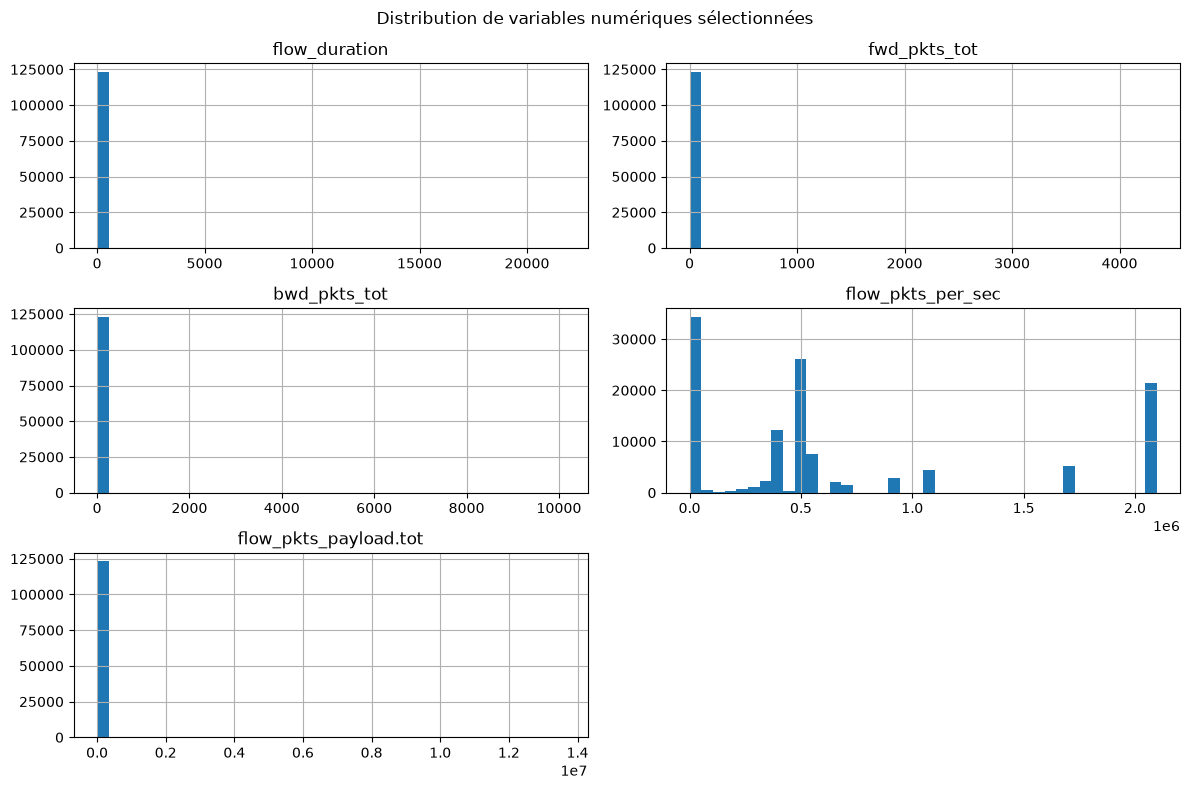

In [46]:
numeric_cols = raw_df.select_dtypes(include=np.number).columns.tolist()
selected_numeric = [c for c in ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec", "flow_pkts_payload.tot"] if c in raw_df.columns]
if not selected_numeric:
    selected_numeric = numeric_cols[:6]
raw_df[selected_numeric].hist(figsize=(12, 8), bins=40)
plt.suptitle("Distribution de variables numériques sélectionnées")
plt.tight_layout()
plt.show()

**Commentaire :** ces histogrammes permettent de repérer les distributions asymétriques et les valeurs très éloignées du centre. Pour le trafic réseau, ces valeurs extrêmes peuvent représenter de véritables comportements (par exemple un grand nombre de paquets), et ne sont donc pas automatiquement des erreurs.

### 5.2 Variables catégorielles

In [47]:
categorical_cols = raw_df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_cols:
    print(f"\n--- {col} : top catégories ---")
    display(raw_df[col].value_counts(dropna=False).head(15))


--- proto : top catégories ---


C:\Users\user\AppData\Local\Temp\ipykernel_2880\2195777717.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = raw_df.select_dtypes(include=["object", "category"]).columns.tolist()


proto
tcp     110427
udp      12633
icmp        57
Name: count, dtype: int64


--- service : top catégories ---


service
-         102861
dns         9753
mqtt        4132
http        3464
ssl         2663
ntp          121
dhcp          50
irc           43
ssh           28
radius         2
Name: count, dtype: int64


--- Attack_type : top catégories ---


Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

## 6. Analyse des classes de trafic

,Effectif,Pourcentage
Attack_type,,
DOS_SYN_Hping,94659,76.89
Thing_Speak,8108,6.59
ARP_poisioning,7750,6.29
MQTT_Publish,4146,3.37
NMAP_UDP_SCAN,2590,2.10
NMAP_XMAS_TREE_SCAN,2010,1.63
NMAP_OS_DETECTION,2000,1.62
NMAP_TCP_scan,1002,0.81
DDOS_Slowloris,534,0.43


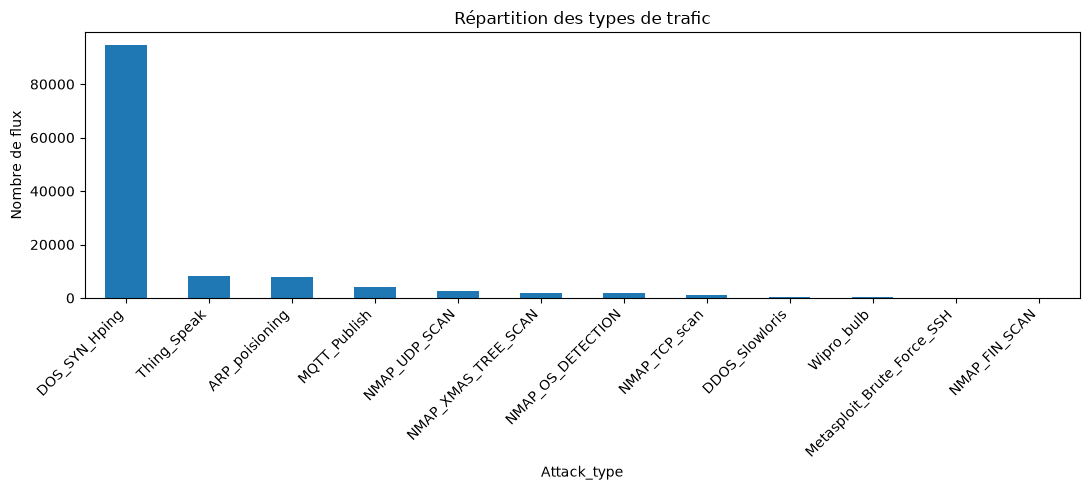

In [48]:
if "Attack_type" in raw_df.columns:
    class_counts = raw_df["Attack_type"].value_counts(dropna=False)
    display(pd.DataFrame({"Effectif": class_counts, "Pourcentage": (class_counts / len(raw_df) * 100).round(2)}))
    class_counts.plot(kind="bar", figsize=(11, 5))
    plt.title("Répartition des types de trafic")
    plt.ylabel("Nombre de flux")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Colonne Attack_type non trouvée.")

**Commentaire :** une forte différence d'effectifs entre catégories signifie que certaines classes sont peu représentées. Nous le documentons ici sans appliquer de rééquilibrage, car cette V1 ne contient pas de modèle.

## 7. Qualité initiale des données

### 7.1 Valeurs manquantes et valeurs infinies

In [49]:
missing_count = raw_df.isna().sum()
missing_table = pd.DataFrame({"Valeurs manquantes": missing_count, "Pourcentage (%)": (missing_count / len(raw_df) * 100).round(3)})
missing_table = missing_table[missing_table["Valeurs manquantes"] > 0].sort_values("Valeurs manquantes", ascending=False)
print("Nombre total de cellules manquantes :", int(raw_df.isna().sum().sum()))
print("Nombre de colonnes avec au moins une valeur manquante :", int((raw_df.isna().sum() > 0).sum()))
display(missing_table)
num_raw = raw_df.select_dtypes(include=np.number)
inf_count = np.isinf(num_raw).sum().sum()
print("Nombre de valeurs infinies dans les colonnes numériques :", int(inf_count))

Nombre total de cellules manquantes : 0
Nombre de colonnes avec au moins une valeur manquante : 0


,Valeurs manquantes,Pourcentage (%)


Nombre de valeurs infinies dans les colonnes numériques : 0


### 7.2 Doublons

In [50]:
duplicate_count = raw_df.duplicated().sum()
print(f"Lignes dupliquées exactes : {duplicate_count:,} ({duplicate_count / len(raw_df):.2%})")

Lignes dupliquées exactes : 0 (0.00%)


### 7.3 Colonnes constantes ou quasi constantes

In [51]:
nunique = raw_df.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()
print("Colonnes constantes (une seule valeur, NaN inclus) :", constant_cols)
low_variation = nunique[nunique <= 5].sort_values()
display(low_variation.to_frame("Nombre de valeurs distinctes"))

Colonnes constantes (une seule valeur, NaN inclus) : ['bwd_URG_flag_count']


,Nombre de valeurs distinctes
bwd_URG_flag_count,1
fwd_URG_flag_count,2
label,2
proto,3
flow_CWR_flag_count,5
flow_ECE_flag_count,5


## 8. Détection exploratoire des valeurs extrêmes (IQR)

La règle IQR signale les observations situées en dessous de Q1 − 1,5×IQR ou au-dessus de Q3 + 1,5×IQR. Cette méthode est utilisée ici comme **signal d'exploration**, pas comme justification de suppression automatique. Les ports et la cible binaire dérivée ne sont pas inclus dans l'analyse.

In [52]:
num_for_iqr = raw_df.select_dtypes(include=np.number).drop(columns=["id.orig_p", "id.resp_p", "label"], errors="ignore")
q1, q3 = num_for_iqr.quantile(0.25), num_for_iqr.quantile(0.75)
iqr = q3 - q1
outlier_mask = num_for_iqr.lt(q1 - 1.5 * iqr) | num_for_iqr.gt(q3 + 1.5 * iqr)
outlier_summary = pd.DataFrame({"Nombre signalé": outlier_mask.sum(), "Pourcentage (%)": (outlier_mask.mean() * 100).round(2)})
outlier_summary = outlier_summary.sort_values("Pourcentage (%)", ascending=False)
print("Colonnes numériques analysées :", num_for_iqr.shape[1])
print("Lignes avec au moins un signal IQR :", int(outlier_mask.any(axis=1).sum()), f"({outlier_mask.any(axis=1).mean():.1%})")
display(outlier_summary.head(20))

Colonnes numériques analysées : 80
Lignes avec au moins un signal IQR : 38295 (31.1%)


,Nombre signalé,Pourcentage (%)
flow_pkts_payload.avg,38116,30.96
bwd_header_size_tot,33148,26.92
bwd_header_size_max,33137,26.92
flow_ACK_flag_count,33083,26.87
bwd_pkts_tot,32364,26.29
bwd_subflow_pkts,32343,26.27
bwd_header_size_min,32065,26.04
fwd_pkts_payload.min,28458,23.11
fwd_pkts_payload.avg,28458,23.11
flow_pkts_payload.tot,28455,23.11


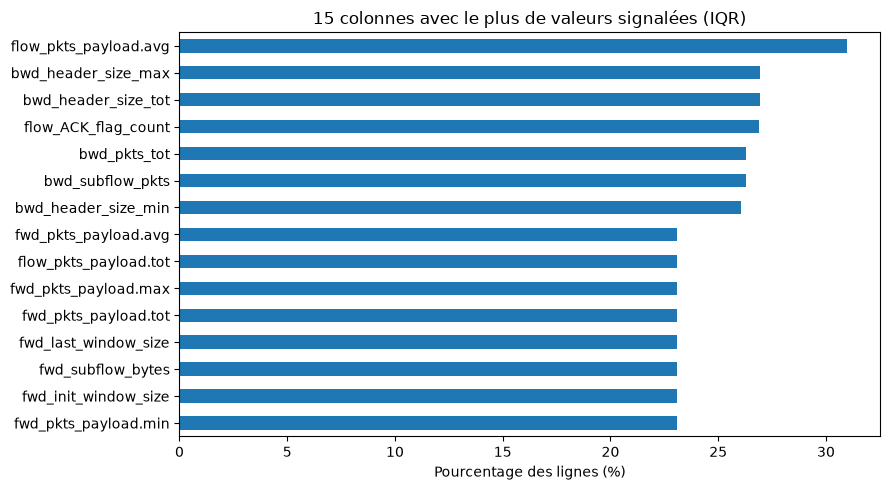

In [53]:
outlier_summary.head(15).sort_values("Pourcentage (%)").plot(kind="barh", y="Pourcentage (%)", figsize=(9, 5), legend=False)
plt.title("15 colonnes avec le plus de valeurs signalées (IQR)")
plt.xlabel("Pourcentage des lignes (%)")
plt.tight_layout()
plt.show()

## 9. Nettoyage initial

Le nettoyage est effectué sur une copie `clean_df` afin de conserver `raw_df` intact et de pouvoir comparer avant/après. Les choix appliqués dans cette V1 :

1. remplacer les valeurs infinies par des valeurs manquantes (`NaN`) ;
2. supprimer les doublons exacts ;
3. remplir les valeurs manquantes numériques par la médiane de la colonne ;
4. remplir les valeurs manquantes catégorielles par la modalité la plus fréquente (si elle existe) ;
5. conserver les colonnes constantes et les valeurs extrêmes dans cette V1, mais les signaler pour une décision ultérieure.

**Important :** les valeurs extrêmes ne sont pas supprimées, car elles peuvent être significatives pour les attaques réseau. Le nettoyage est transparent et les choix pourront être revus dans la V2.

In [54]:
clean_df = raw_df.copy()
# 1) Infinis -> NaN, uniquement dans les colonnes numériques
clean_df.replace([np.inf, -np.inf], np.nan, inplace=True)
# 2) Supprimer les doublons exacts
before_duplicates = len(clean_df)
clean_df.drop_duplicates(inplace=True)
removed_duplicates = before_duplicates - len(clean_df)
# 3-4) Imputation simple pour obtenir une copie exploitable sans valeurs manquantes
numeric_clean_cols = clean_df.select_dtypes(include=np.number).columns
categorical_clean_cols = clean_df.select_dtypes(include=["object", "category"]).columns
for col in numeric_clean_cols:
    if clean_df[col].isna().any():
        median_value = clean_df[col].median()
        if pd.notna(median_value):
            clean_df[col] = clean_df[col].fillna(median_value)
for col in categorical_clean_cols:
    if clean_df[col].isna().any():
        mode_values = clean_df[col].mode(dropna=True)
        if not mode_values.empty:
            clean_df[col] = clean_df[col].fillna(mode_values.iloc[0])
print(f"Doublons supprimés : {removed_duplicates:,}")
print("Taille avant nettoyage :", raw_df.shape)
print("Taille après nettoyage :", clean_df.shape)
print("Valeurs manquantes restantes :", int(clean_df.isna().sum().sum()))
print("Valeurs infinies restantes :", int(np.isinf(clean_df.select_dtypes(include=np.number)).sum().sum()))

Doublons supprimés : 0
Taille avant nettoyage : (123117, 86)
Taille après nettoyage : (123117, 86)
Valeurs manquantes restantes : 0
Valeurs infinies restantes : 0


C:\Users\user\AppData\Local\Temp\ipykernel_2880\1774447004.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_clean_cols = clean_df.select_dtypes(include=["object", "category"]).columns


### 9.1 Comparaison avant / après

In [55]:
comparison = pd.DataFrame({
    "Avant": [len(raw_df), raw_df.shape[1], int(raw_df.isna().sum().sum()), int(raw_df.duplicated().sum())],
    "Après": [len(clean_df), clean_df.shape[1], int(clean_df.isna().sum().sum()), int(clean_df.duplicated().sum())]
}, index=["Lignes", "Colonnes", "Cellules manquantes", "Doublons"])
display(comparison)

,Avant,Après
Lignes,123117,123117
Colonnes,86,86
Cellules manquantes,0,0
Doublons,0,0


### 9.2 Variables constantes après nettoyage

In [56]:
clean_constant_cols = [c for c in clean_df.columns if clean_df[c].nunique(dropna=False) <= 1]
print("Colonnes constantes conservées :", clean_constant_cols)
print("Elles sont signalées mais non supprimées, car la V1 vise à documenter les données avant de décider des variables à retirer.")

Colonnes constantes conservées : ['bwd_URG_flag_count']
Elles sont signalées mais non supprimées, car la V1 vise à documenter les données avant de décider des variables à retirer.


## 10. Séparation train/test et équilibrage du train

Après le nettoyage, nous séparons les données en **80 % pour l’entraînement** et **20 % pour le test**, avec une séparation stratifiée pour conserver la proportion des deux classes dans chaque partie. L’équilibrage est appliqué **uniquement au train** par sous-échantillonnage aléatoire de la classe majoritaire (undersampling). Le jeu de test reste intact et garde sa distribution naturelle afin d’évaluer plus tard le modèle dans des conditions réalistes.

La colonne `Attack_type` est exclue des variables explicatives, car la cible `label` est construite à partir de cette colonne : la conserver créerait une fuite d’information. Cette étape prépare les données ; aucun modèle n’est entraîné dans cette V1.

In [57]:
# Définir la cible et les variables explicatives (éviter la fuite par Attack_type)
y = clean_df["label"].copy()
X = clean_df.drop(columns=["label", "Attack_type"], errors="ignore").copy()

# Séparation stratifiée 80/20 avec une graine fixe pour reproductibilité
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Dimensions initiales des ensembles :")
print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print("Répartition train avant équilibrage :")
display(y_train.value_counts().sort_index().rename_axis("label").to_frame("Effectif"))
print("Répartition test (non modifiée) :")
display(y_test.value_counts().sort_index().rename_axis("label").to_frame("Effectif"))


Dimensions initiales des ensembles :
Train : (98493, 84) | Test : (24624, 84)
Répartition train avant équilibrage :


,Effectif
label,
0,10006
1,88487


Répartition test (non modifiée) :


,Effectif
label,
0,2501
1,22123


### 10.1 Équilibrer uniquement le train (undersampling)

Nous gardons le même nombre d’exemples pour chaque classe dans l’ensemble d’entraînement, en réduisant aléatoirement la classe la plus représentée au nombre d’exemples de la classe minoritaire. Cela évite de modifier le test et ne crée pas de copies artificielles. La contrepartie est que des exemples de la classe majoritaire sont écartés du train.

In [58]:
# Sous-échantillonnage aléatoire de la classe majoritaire dans le train uniquement
train_parts = []
min_class_size = y_train.value_counts().min()
for class_value in sorted(y_train.unique()):
    class_indices = y_train[y_train == class_value].sample(
        n=min_class_size, random_state=42
    ).index
    train_parts.append(X_train.loc[class_indices])

X_train_balanced = pd.concat(train_parts).sample(frac=1, random_state=42)
y_train_balanced = y_train.loc[X_train_balanced.index]

print("Train équilibré :")
display(y_train_balanced.value_counts().sort_index().rename_axis("label").to_frame("Effectif"))
print(f"Dimensions train équilibré : {X_train_balanced.shape}")
print(f"Dimensions test inchangé : {X_test.shape}")


Train équilibré :


,Effectif
label,
0,10006
1,10006


Dimensions train équilibré : (20012, 84)
Dimensions test inchangé : (24624, 84)


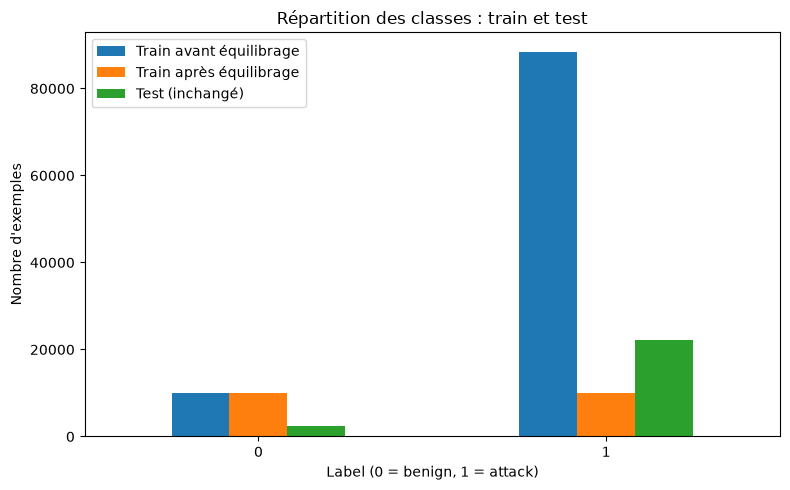

In [59]:
# Visualiser les distributions avant/après équilibrage du train
counts_plot = pd.DataFrame({
    "Train avant équilibrage": y_train.value_counts().sort_index(),
    "Train après équilibrage": y_train_balanced.value_counts().sort_index(),
    "Test (inchangé)": y_test.value_counts().sort_index()
}).fillna(0)
counts_plot.plot(kind="bar", figsize=(8, 5))
plt.title("Répartition des classes : train et test")
plt.xlabel("Label (0 = benign, 1 = attack)")
plt.ylabel("Nombre d'exemples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Corrélations entre variables numériques

La matrice de corrélation de Pearson est calculée sur un sous-ensemble de variables numériques afin d'éviter un graphique illisible. Une corrélation élevée peut indiquer des variables redondantes, mais ne signifie pas à elle seule qu'une variable doit être supprimée.

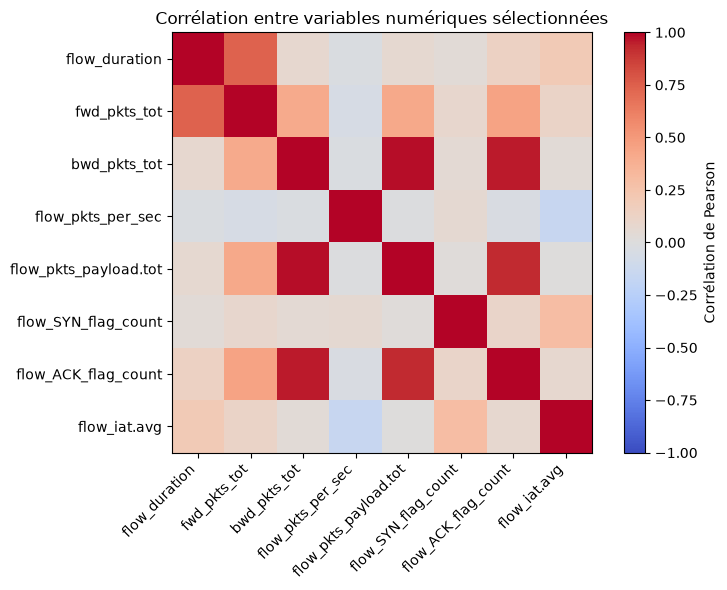

In [60]:
corr_cols = [c for c in ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec", "flow_pkts_payload.tot", "flow_SYN_flag_count", "flow_ACK_flag_count", "flow_iat.avg"] if c in clean_df.columns]
if len(corr_cols) >= 2:
    corr = clean_df[corr_cols].corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
    ax.set_yticks(range(len(corr_cols)), corr_cols)
    fig.colorbar(im, ax=ax, label="Corrélation de Pearson")
    ax.set_title("Corrélation entre variables numériques sélectionnées")
    plt.tight_layout()
    plt.show()
else:
    print("Pas assez de colonnes numériques sélectionnées pour la matrice de corrélation.")

## 12. Conclusion de la V1 (analyse, nettoyage et préparation des ensembles)

Dans cette première version, nous avons chargé le dataset RT-IoT2022, examiné ses dimensions et types, étudié les distributions numériques et catégorielles, visualisé les catégories de trafic, et analysé les valeurs manquantes, infinies, doublons, variables constantes et valeurs extrêmes.

Le nettoyage initial a été réalisé sans modifier la source : les doublons exacts ont été retirés, les infinis convertis en valeurs manquantes puis les valeurs manquantes imputées par médiane (numérique) ou mode (catégorielle). Les outliers et les colonnes constantes sont conservés et signalés plutôt que supprimés automatiquement.

**Limites de cette V1 :** certaines valeurs extrêmes peuvent être légitimes, l'imputation médiane/mode est simple et n'a pas encore été comparée à d'autres méthodes, et aucune performance prédictive n'est mesurée. **Étapes envisagées pour la suite :** décider du traitement des variables constantes/redundantes, préparer les variables catégorielles et numériques pour la modélisation, puis construire et évaluer un modèle dans une version ultérieure.